# Section 1 — A Shop's Catalogue

Build the shop's catalogue: 1,000 SKUs (product + brand + pack size) from the hand-written `catalog_data.py`,
the same shop every run for a given seed, with every product stocked at least once.

**Done when:** the reference check at the end prints `identical, item for item: True`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from typing import Optional

from thilimarketbasket.catalog_data import CATEGORIES

## The raw material
`CATEGORIES` holds the products, invented brands and pack sizes, each with a weight. The brands are invented so a
model's prior knowledge of real brands can't blur what it learns from our baskets.

In [2]:
summary = pd.DataFrame(
    [{"category": name,
      "products": len(spec["products"]),
      "brands": len(spec["brands"]),
      "default pack sizes": ", ".join(spec["sizes"])}
     for name, spec in CATEGORIES.items()]
).set_index("category")

print(f"{summary['products'].sum()} products in {len(summary)} categories\n")
summary

127 products in 12 categories



,products,brands,default pack sizes
category,,,
Staples,14,6,"500 g, 1 kg, 5 kg"
Pulses,10,6,"500 g, 1 kg, 5 kg"
Oils and Ghee,7,6,"500 ml, 1 L, 5 L"
Spices,14,6,"sachet 10 g, 100 g, 200 g"
Dairy and Eggs,7,5,"200 g, 500 g"
Bakery and Breakfast,7,5,"100 g, 200 g, 400 g"
Snacks and Instant Food,10,6,"Rs 5 pack, Rs 10 pack, 150 g"
Beverages,10,6,"250 g, 500 g"
Fresh Produce,17,0,"500 g, 1 kg"


In [3]:
pulses = CATEGORIES["Pulses"]
print("brands:", ", ".join(pulses["brands"]))
print("pack sizes:", ", ".join(pulses["sizes"]))
print("\nproducts:")
for product in pulses["products"]:
    print("  ", product)

brands: Surya Grains, Kaveri Valley, Annadata, Maitri Foods, Shubham Select, Pragati
pack sizes: 500 g, 1 kg, 5 kg

products:
   ('Toor Dal', 20)
   ('Moong Dal', 10)
   ('Chana Dal', 8)
   ('Urad Dal', 8)
   ('Masoor Dal', 7)
   ('Rajma', 4)
   ('Kabuli Chana', 4)
   ('Green Moong', 3)
   ('Black Chana', 3)
   ('Lobia', 2)


## From products to SKUs
One product becomes many SKUs: every brand × every pack size.

In [4]:
brands = list(pulses["brands"])
sizes = list(pulses["sizes"])
possible = [f"{brand} Toor Dal {size}" for brand in brands for size in sizes]

print(f"{len(brands)} brands x {len(sizes)} pack sizes = {len(possible)} possible SKUs of Toor Dal, for example:")
for name in possible[:6]:
    print("  ", name)

6 brands x 3 pack sizes = 18 possible SKUs of Toor Dal, for example:
   Surya Grains Toor Dal 500 g
   Surya Grains Toor Dal 1 kg
   Surya Grains Toor Dal 5 kg
   Kaveri Valley Toor Dal 500 g
   Kaveri Valley Toor Dal 1 kg
   Kaveri Valley Toor Dal 5 kg


A real shop doesn't stock every brand, so each product gets `brands_per_product` brands, with bigger brands
more likely to be picked.

In [5]:
@dataclass(frozen=True)
class Item:
    """One SKU: a product, in one brand and one pack size."""
    name: str               # the full name a model will read, e.g. "Surya Grains Toor Dal 1 kg"
    base: str               # the product without brand or size, e.g. "Toor Dal"
    category: str           # e.g. "Pulses"
    brand: Optional[str]    # None for loose goods such as fresh produce
    size: str               # e.g. "1 kg", "Rs 2 sachet", "dozen"


def split(product):
    """A product is (name, weight) or (name, weight, {size: weight}) when it has its own pack sizes."""
    return product if len(product) == 3 else (product[0], product[1], None)


def all_skus(brands_per_product, rng):
    skus = []
    for category, spec in CATEGORIES.items():
        brand_names = list(spec["brands"])
        brand_weights = np.array(list(spec["brands"].values()), dtype=float)
        for product in spec["products"]:
            base, _, own_sizes = split(product)
            sizes = own_sizes or spec["sizes"]
            if brand_names:
                # pick this many brands, big brands more likely, none twice
                k = min(brands_per_product, len(brand_names))
                picked = rng.choice(len(brand_names), size=k, replace=False,
                                    p=brand_weights / brand_weights.sum())
                brands = [brand_names[i] for i in sorted(picked)]
            else:
                brands = [None]          # sold loose
            for brand in brands:
                for size in sizes:
                    name = " ".join(part for part in (brand, base, size) if part)
                    skus.append(Item(name=name, base=base, category=category, brand=brand, size=size))
    return skus

### Aside: NumPy's modern random generator
`np.random.default_rng(seed)` uses PCG64 — faster and statistically better than the legacy `np.random.seed()`
(Mersenne Twister). Same seed → same numbers, which is what makes the shop reproducible.

In [6]:
rng = np.random.default_rng(seed=42)
print("Uniform Floats [0, 1):\n", rng.random(size=5))
print("\nIntegers [1, 100):\n", rng.integers(low=1, high=100, size=5))
print("\nStandard Normal:\n", rng.standard_normal(size=5))

Uniform Floats [0, 1):
 [0.77395605 0.43887844 0.85859792 0.69736803 0.09417735]

Integers [1, 100):
 [53 97 73 76 72]

Standard Normal:
 [-0.01680116 -0.85304393  0.87939797  0.77779194  0.0660307 ]


In [7]:
rng = np.random.default_rng(0)
pool = all_skus(4, rng)

print(f"{len(pool):,} SKUs the shop could stock with 4 brands per product\n")
for item in pool[:5]:
    print("  ", item)

1,127 SKUs the shop could stock with 4 brands per product

   Item(name='Kaveri Valley Basmati Rice 500 g', base='Basmati Rice', category='Staples', brand='Kaveri Valley', size='500 g')
   Item(name='Kaveri Valley Basmati Rice 1 kg', base='Basmati Rice', category='Staples', brand='Kaveri Valley', size='1 kg')
   Item(name='Kaveri Valley Basmati Rice 5 kg', base='Basmati Rice', category='Staples', brand='Kaveri Valley', size='5 kg')
   Item(name='Maitri Foods Basmati Rice 500 g', base='Basmati Rice', category='Staples', brand='Maitri Foods', size='500 g')
   Item(name='Maitri Foods Basmati Rice 1 kg', base='Basmati Rice', category='Staples', brand='Maitri Foods', size='1 kg')


## Choosing the catalogue
Two rules: every product appears at least once; the rest are filled at random. We keep 1,000 of the pool,
because a shop stocks a range, the catalogue defines what can be bought, and its size sets the cost of later steps.

In [8]:
def my_make_catalog(n_items=1000, brands_per_product=4, seed=0):
    rng = np.random.default_rng(seed)
    pool = all_skus(brands_per_product, rng)

    by_product = {}   # (category, product) -> positions of its SKUs in the pool
    for position, sku in enumerate(pool):
        by_product.setdefault((sku.category, sku.base), []).append(position)

    if n_items < len(by_product):
        raise ValueError(f"need at least {len(by_product)} items to cover every product, got {n_items}")
    if n_items > len(pool):
        raise ValueError(f"only {len(pool)} SKUs are possible with brands_per_product={brands_per_product}; "
                         f"ask for fewer items or raise brands_per_product")

    chosen = {int(rng.choice(positions)) for positions in by_product.values()}   # one SKU for every product
    rest = [i for i in range(len(pool)) if i not in chosen]
    chosen |= {int(i) for i in rng.choice(rest, size=n_items - len(chosen), replace=False)}
    return [pool[i] for i in sorted(chosen)]


catalog = my_make_catalog()
print(f"{len(catalog):,} items in the catalogue")

1,000 items in the catalogue


## Check against the reference

In [9]:
from thilimarketbasket.generate import make_catalog as reference_make_catalog

reference = reference_make_catalog()
mine = [(i.name, i.base, i.category, i.brand, i.size) for i in catalog]
theirs = [(i.name, i.base, i.category, i.brand, i.size) for i in reference]

print("same number of items:", len(mine) == len(theirs))
print("identical, item for item:", mine == theirs)
print("every name is unique:", len({i.name for i in catalog}) == len(catalog))

same number of items: True
identical, item for item: True
every name is unique: True


## What the shop looks like

In [10]:
df = pd.DataFrame([vars(item) for item in catalog])
df.sample(10, random_state=1).sort_values(["category", "name"]).reset_index(drop=True)

,name,base,category,brand,size
0,Morning Crisp Bread 400 g,Bread,Bakery and Breakfast,Morning Crisp,400 g
1,Gokul Fresh Curd 200 g,Curd,Dairy and Eggs,Gokul Fresh,200 g
2,Shuddh Phenyl 2 L,Phenyl,Household and Cleaning,Shuddh,2 L
3,Shuddh Toilet Cleaner 1 L,Toilet Cleaner,Household and Cleaning,Shuddh,1 L
4,Dhara Fresh Groundnut Oil 500 ml,Groundnut Oil,Oils and Ghee,Dhara Fresh,500 ml
5,Golden Drop Coconut Oil 1 L,Coconut Oil,Oils and Ghee,Golden Drop,1 L
6,Pure Petal Sanitary Pads pack of 8,Sanitary Pads,Personal Care,Pure Petal,pack of 8
7,Masala Mantra Red Chilli Powder 200 g,Red Chilli Powder,Spices,Masala Mantra,200 g
8,Masala Mantra Sambar Powder 200 g,Sambar Powder,Spices,Masala Mantra,200 g
9,Kaveri Valley Besan 500 g,Besan,Staples,Kaveri Valley,500 g


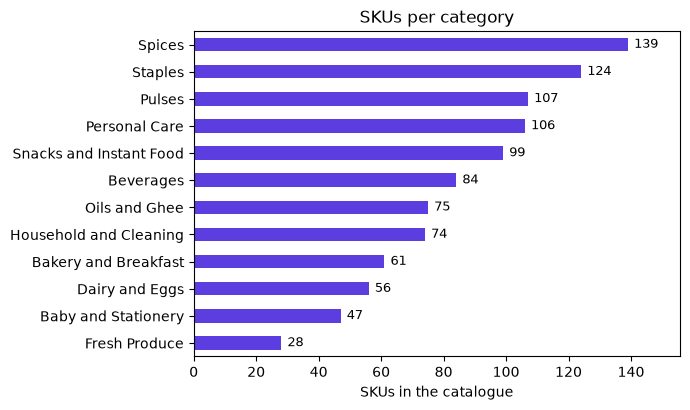

In [11]:
per_category = df.groupby("category").size().sort_values()

fig, ax = plt.subplots(figsize=(7, 4.2))
per_category.plot.barh(ax=ax, color="#5b3de0")
ax.set_xlabel("SKUs in the catalogue")
ax.set_ylabel("")
ax.set_title("SKUs per category")
for position, value in enumerate(per_category):
    ax.text(value + 2, position, str(value), va="center", fontsize=9)
ax.set_xlim(0, per_category.max() * 1.12)
plt.tight_layout()
plt.show()

SKUs per product: fewest 1, median 8, most 12
loose goods with no brand: 28 SKUs
sachets and small rupee packs: 116 SKUs


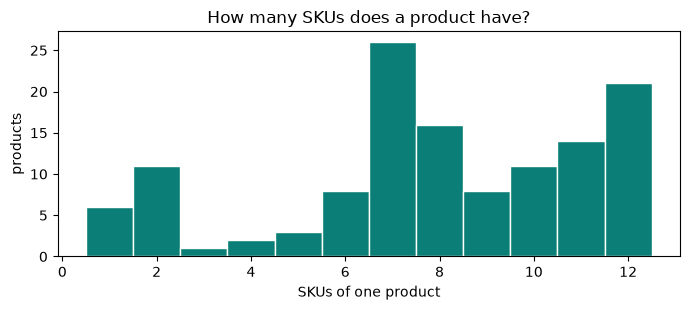

In [12]:
per_product = df.groupby(["category", "base"]).size()

print(f"SKUs per product: fewest {per_product.min()}, median {int(per_product.median())}, most {per_product.max()}")
print(f"loose goods with no brand: {df['brand'].isna().sum()} SKUs")
print(f"sachets and small rupee packs: {df['size'].str.contains('sachet|^Rs ', regex=True).sum()} SKUs")

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(per_product, bins=range(1, int(per_product.max()) + 2), color="#0b7f77", edgecolor="white", align="left")
ax.set_xlabel("SKUs of one product")
ax.set_ylabel("products")
ax.set_title("How many SKUs does a product have?")
plt.tight_layout()
plt.show()

**Notice:** spices have the most SKUs (14 products, 6 brands, a sachet size), fresh produce the fewest (no brands).
A product's sales get shared among its SKUs — section 2 deals with that.

## Try it

In [13]:
for k in (1, 2, 4, 6):
    pool_k = all_skus(k, np.random.default_rng(0))
    print(f"brands_per_product={k}: {len(pool_k):>5,} possible SKUs")

brands_per_product=1:   305 possible SKUs
brands_per_product=2:   579 possible SKUs
brands_per_product=4: 1,127 possible SKUs
brands_per_product=6: 1,565 possible SKUs


In [14]:
for bad in (5000, 100):
    try:
        my_make_catalog(n_items=bad)
    except ValueError as error:
        print(f"n_items={bad}: ValueError: {error}")

n_items=5000: ValueError: only 1127 SKUs are possible with brands_per_product=4; ask for fewer items or raise brands_per_product
n_items=100: ValueError: need at least 127 items to cover every product, got 100


## What I built
A function that turns hand-written products, brands and pack sizes into a catalogue of 1,000 SKUs — the same
one every time for a given seed, with every product stocked at least once — identical to the reference.

## Test yourself

**1. Why build the catalogue at SKU level (brand + pack size) instead of just listing products?**
A shop stocks and sells SKUs, not abstract products: you buy one brand of toor dal in one size. SKU names also give
the language model something to read, so later we can see whether it treats two brands of the same dal as relatives.

**2. Why does `my_make_catalog` first pick one SKU for every product before filling the rest at random?**
So no product can disappear by bad luck. With 127 products and 1,000 slots, a purely random pick could leave a
product (or even a small category) with no SKU at all. Guaranteeing one each keeps the whole shop represented.

**3. Why are the brands invented?**
A model trained on internet text already has beliefs about real brands and what goes with them. Invented brands mean
anything it links together must have come from our baskets, not from what it read before.

## My notes

(Dakshitha to fill)